# Proposed Data Science Solution for Nata Supermarket

#### Dataset Description 

The dataset contains biographical and shopping details of customers from Nata Supermarkets, spanning three years (2012-2014). Key customer attributes include personal information (e.g., age, education, income, marital status, number of children) and shopping behavior (e.g., spending on different product categories, promotional participation, frequency of online and store purchases).

#### Data Dictionary 
* ID: Customer unique ID (or identification number) - Object
* Year_Birth: Customer birth year - Continuous
* Education: Customer education level - Object
* Marital_Status: Customer marital status - Object
* Income: Customer income level - Continuous
* Kidhome: Number of kids in the household - Continuous
* Teenhome: Number of teenagers in the household - Continuous
* Dt_Customer: Date of enrolment with the supermarket - Object
* Recency: Number of days since the last purchase - Continuous
* MntWines: Amount spent on wine in last two years - Continuous
* MntFruits: Amount spent on fruits in the last two years - Continuous
* MntMeatProducts: Amount spent on meat in the last two years - Continuous
* MntFishProducts: Amount spent on fish in the last two years - Continuous
* MntSweetProducts: Amount spent on sweets in the last two years - Continuous
* MntGoldProds: Amount spent on gold in the last two years - Continuous
* NumDealsPurchases: Number of purchases made on discount - Continuous
* NumWebPurchases: Number of purchases made through the website - Continuous
* NumCatalogPurchases: Number of purchases made through the catalogue - Continuous
* NumStorePurchases: Number of purchases made through the store - Continuous
* NumWebVisitsMonth: Number of visits to the website in the last month - Continuous
* AcceptedCmp1: Enter 1 if accepted 1st campaign; otherwise, 0 - Binary
* AcceptedCmp2: Enter 1 if accepted 2nd campaign; otherwise, 0 - Binary
* AcceptedCmp3: Enter 1 if accepted 3rd campaign; otherwise, 0 - Binary
* AcceptedCmp4: Enter 1 if accepted 4th campaign; otherwise, 0 - Binary
* AcceptedCmp5: Enter 1 if accepted 5th campaign; otherwise, 0 - Binary
* Complain: Enter 1 if the customer complained in the last two years; otherwise, 0 - Binary

In [4]:
import os
os.environ["OMP_NUM_THREADS"] = "4"

In [5]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns  
from datetime import datetime
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from kneed import KneeLocator
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, classification_report
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.eval_measures import rmse
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.stattools import adfuller
import plotly.graph_objs as go

In [6]:
df = pd.read_csv("C:\\Users\\amand\\Downloads\\YEAR 2\\Term 3\\Business Process Support\\nata.csv")

## Data Cleaning and Preprocessing

In [8]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,09/04/2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,03/08/2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,02/10/2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [9]:
df.shape

(2240, 29)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [11]:
df.drop(columns=["ID", "Z_CostContact", "Complain", "Z_Revenue", "Teenhome", "Kidhome", "Response"], inplace=True)

In [12]:
df["Dt_Customer"] = df["Dt_Customer"].astype(str).str.replace("-", "/", regex=True)
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d/%m/%Y", dayfirst=True, errors="coerce")

In [13]:
df["Income"] = df["Income"].fillna(df["Income"].median())

In [14]:
df.isnull().sum()

Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
dtype: int64

In [15]:
current_year = datetime.now().year
df["Age"] = current_year - df["Year_Birth"]

In [16]:
df.duplicated().sum()

201

In [17]:
df.drop_duplicates(inplace=True)

In [18]:
Q1 = df["Income"].quantile(0.25)
Q3 = df["Income"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df["Income"] >= lower_bound) & (df["Income"] <= upper_bound)]

In [19]:
df.head()

,Year_Birth,Education,Marital_Status,Income,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Age
0,1957,Graduation,Single,58138.0,2012-04-09,58,635,88,546,172,...,8,10,4,7,0,0,0,0,0,68
1,1954,Graduation,Single,46344.0,2014-08-03,38,11,1,6,2,...,1,1,2,5,0,0,0,0,0,71
2,1965,Graduation,Together,71613.0,2013-08-21,26,426,49,127,111,...,8,2,10,4,0,0,0,0,0,60
3,1984,Graduation,Together,26646.0,2014-10-02,26,11,4,20,10,...,2,0,4,6,0,0,0,0,0,41
4,1981,PhD,Married,58293.0,2014-01-19,94,173,43,118,46,...,5,3,6,5,0,0,0,0,0,44


In [20]:
cols = df.columns.tolist()
age_index = cols.index('Age')  
year_birth_index = cols.index('Year_Birth') 

cols.remove('Age')

cols.insert(year_birth_index + 1, 'Age')

df = df[cols]

print(df.columns)

Index(['Year_Birth', 'Age', 'Education', 'Marital_Status', 'Income',
       'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3',
       'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2'],
      dtype='object')


***

## Exploratory Data Analysis (EDA)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2031 entries, 0 to 2239
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Year_Birth           2031 non-null   int64         
 1   Age                  2031 non-null   int64         
 2   Education            2031 non-null   object        
 3   Marital_Status       2031 non-null   object        
 4   Income               2031 non-null   float64       
 5   Dt_Customer          2031 non-null   datetime64[ns]
 6   Recency              2031 non-null   int64         
 7   MntWines             2031 non-null   int64         
 8   MntFruits            2031 non-null   int64         
 9   MntMeatProducts      2031 non-null   int64         
 10  MntFishProducts      2031 non-null   int64         
 11  MntSweetProducts     2031 non-null   int64         
 12  MntGoldProds         2031 non-null   int64         
 13  NumDealsPurchases    2031 non-null   i

In [24]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Year_Birth,2031.0,NaN,NaN,NaN,1968.753323,1893.0,1959.0,1970.0,1977.0,1996.0,11.989926
Age,2031.0,NaN,NaN,NaN,56.246677,29.0,48.0,55.0,66.0,132.0,11.989926
Education,2031,5,Graduation,1022,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_Status,2031,8,Married,785,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Income,2031.0,NaN,NaN,NaN,51683.792713,1730.0,35686.0,51381.5,68117.5,113734.0,20599.686377
Dt_Customer,2031,NaN,NaN,NaN,2013-07-13 23:15:19.940915968,2012-01-08 00:00:00,2013-01-21 12:00:00,2013-07-14 00:00:00,2014-01-01 12:00:00,2014-12-06 00:00:00,NaN
Recency,2031.0,NaN,NaN,NaN,49.098474,0.0,24.0,49.0,74.0,99.0,28.964054
MntWines,2031.0,NaN,NaN,NaN,304.422452,0.0,23.5,177.0,504.5,1493.0,336.028618
MntFruits,2031.0,NaN,NaN,NaN,26.437223,0.0,2.0,8.0,33.0,199.0,39.876903
MntMeatProducts,2031.0,NaN,NaN,NaN,165.966519,0.0,16.0,68.0,229.0,1725.0,221.065915


In [25]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

In [26]:
for col in cat_cols:
    print(f"\nValue Counts for {col}:")
    print(df[col].value_counts().head(10))


Value Counts for Education:
Education
Graduation    1022
PhD            438
Master         336
2n Cycle       186
Basic           49
Name: count, dtype: int64

Value Counts for Marital_Status:
Marital_Status
Married     785
Together    513
Single      445
Divorced    212
Widow        70
Alone         3
Absurd        2
YOLO          1
Name: count, dtype: int64


### Demographics
***

#### Age Distribution

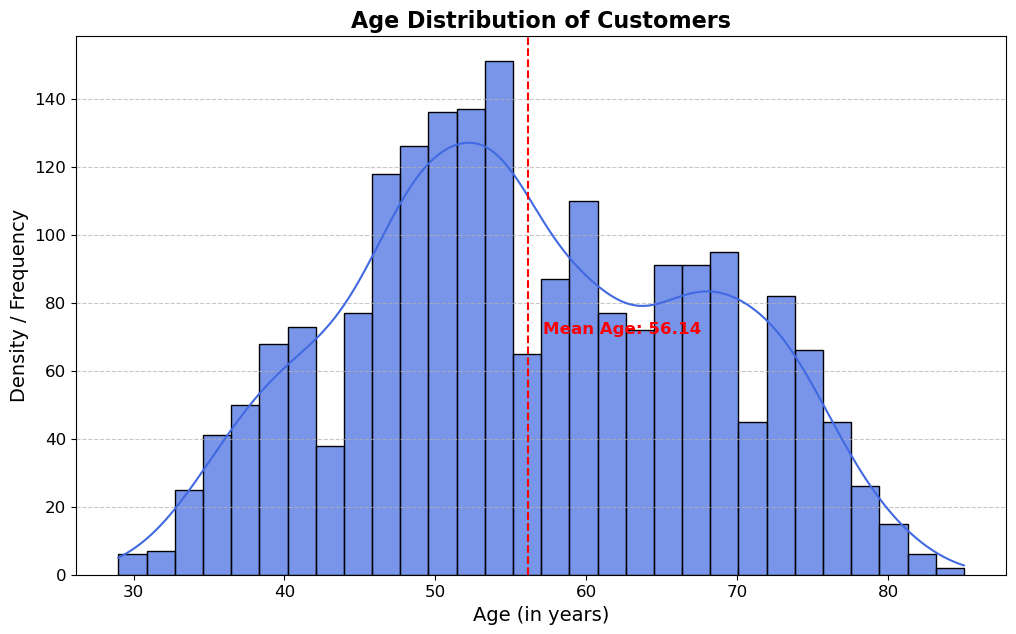

In [29]:
df['Age'] = 2025 - df['Year_Birth']

df = df[df['Age'] < 100]

plt.figure(figsize=(12, 7))
ax = sns.histplot(df['Age'], bins=30, kde=True, color='royalblue', edgecolor='black', alpha=0.7)

mean_age = df['Age'].mean()

plt.axvline(mean_age, color='red', linestyle='dashed', linewidth=1.5)

plt.text(mean_age + 1, df['Age'].value_counts().max() * 0.9, 
         f'Mean Age: {mean_age:.2f}', 
         color='red', fontsize=12, fontweight='bold')

plt.title('Age Distribution of Customers', fontsize=16, fontweight='bold')
plt.xlabel('Age (in years)', fontsize=14)
plt.ylabel('Density / Frequency', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

#### Income Distribution

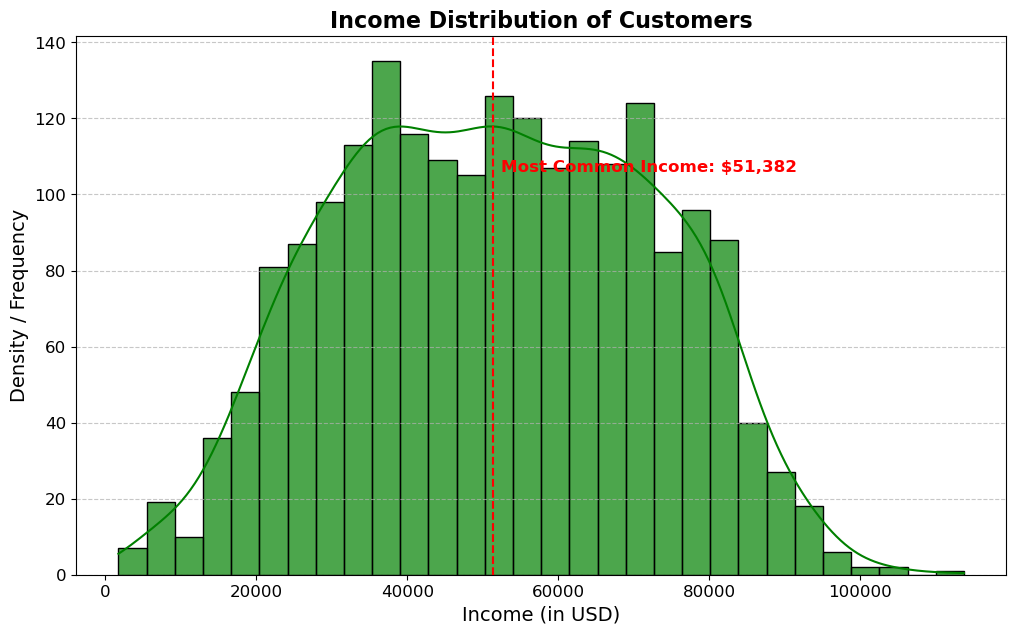

In [31]:
plt.figure(figsize=(12, 7))
ax = sns.histplot(df['Income'], bins=30, kde=True, color='green', edgecolor='black', alpha=0.7)

kde_x, kde_y = ax.lines[0].get_data()

mode_income = df['Income'].mode()[0]  # Most frequently occurring income
most_common_range = df['Income'].value_counts().idxmax()

plt.axvline(most_common_range, color='red', linestyle='dashed', linewidth=1.5)
plt.text(most_common_range + 1000, max(kde_y) * 0.9, 
         f'Most Common Income: ${most_common_range:,.0f}', 
         color='red', fontsize=12, fontweight='bold')

plt.title('Income Distribution of Customers', fontsize=16, fontweight='bold')
plt.xlabel('Income (in USD)', fontsize=14)
plt.ylabel('Density / Frequency', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show plot
plt.show()

#### Marital Status Distribution

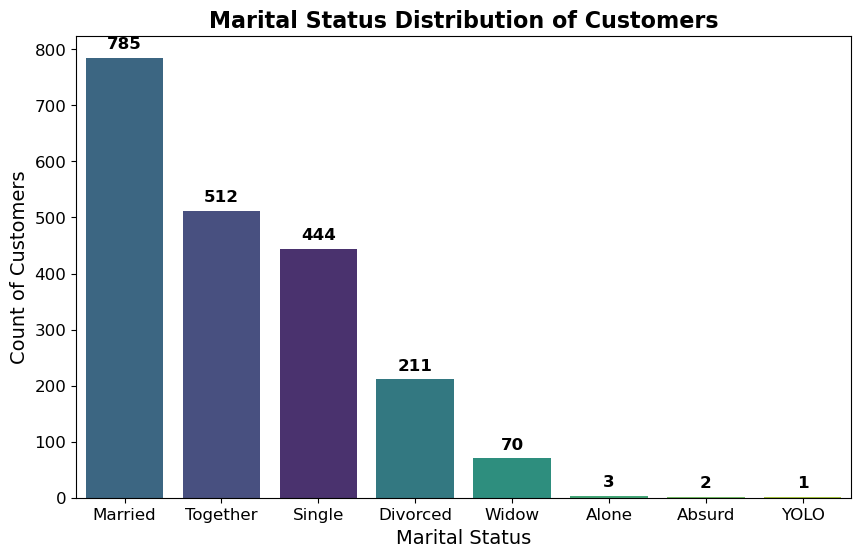

In [33]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(x='Marital_Status', data=df, hue='Marital_Status', palette='viridis', order=df['Marital_Status'].value_counts().index, legend=False)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', fontsize=12, fontweight='bold', color='black', 
                xytext=(0, 10), textcoords='offset points')

plt.title('Marital Status Distribution of Customers', fontsize=16, fontweight='bold')
plt.xlabel('Marital Status', fontsize=14)
plt.ylabel('Count of Customers', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.show()


#### Distribution of Numerical Variables

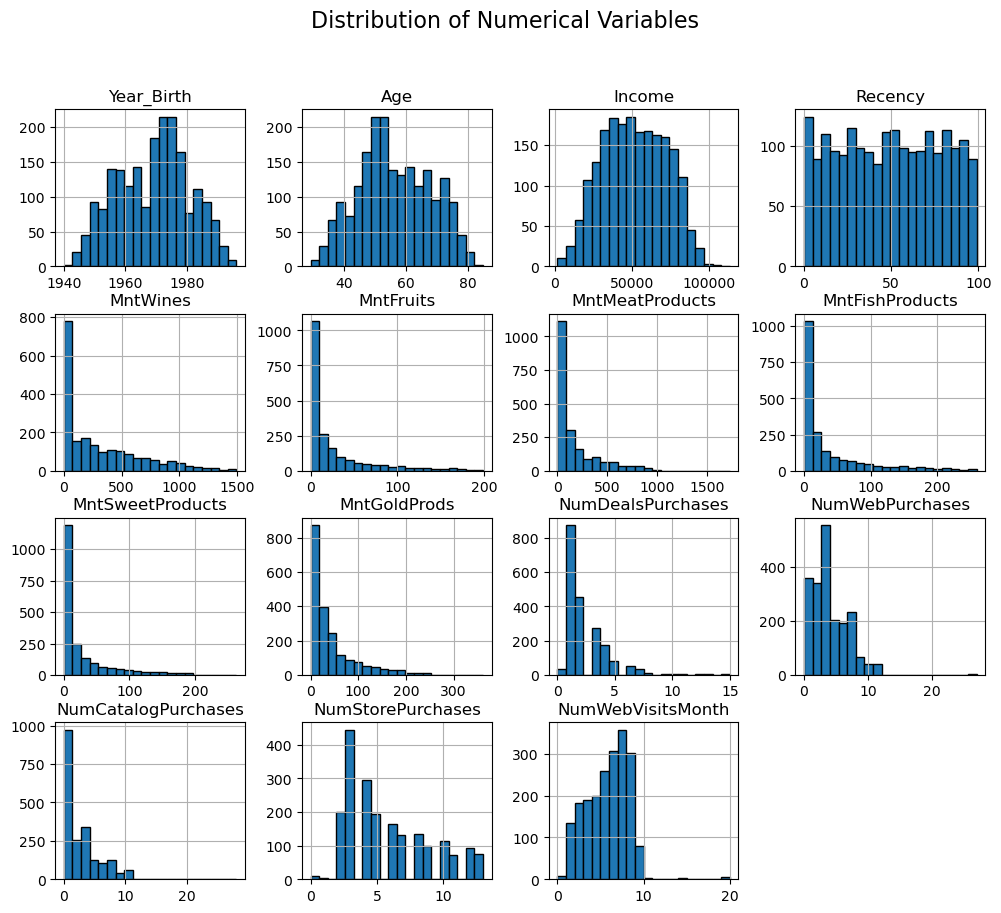

In [35]:
excluded_columns = ["AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "AcceptedCmp1", "AcceptedCmp2"]
numerical_columns = [col for col in df.select_dtypes(include=['number']).columns if col not in excluded_columns]

df[numerical_columns].hist(figsize=(12, 10), bins=20, edgecolor='black')
plt.suptitle("Distribution of Numerical Variables", fontsize=16)
plt.show()

### Spending Behavior
***

#### Spending by Product Category

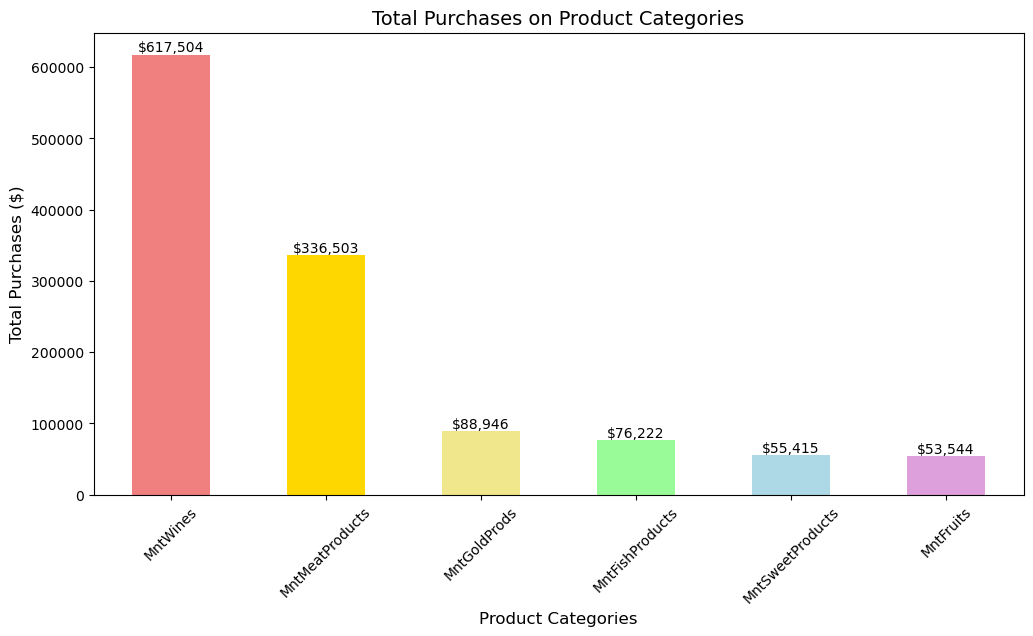

In [38]:
plt.figure(figsize=(12, 6))
spending = df[['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum().sort_values(ascending=False)
ax = spending.plot(kind='bar', color=['#f08080', '#ffd700', '#f0e68c', '#98fb98', '#add8e6', '#dda0dd'])
plt.title('Total Purchases on Product Categories', fontsize=14)
plt.xlabel('Product Categories', fontsize=12)
plt.ylabel('Total Purchases ($)', fontsize=12)
plt.xticks(rotation=45)

for p in ax.patches:
    ax.annotate(f'${p.get_height():,.0f}', (p.get_x() + p.get_width() / 2, p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black')
plt.show()

#### Spending by Age Group

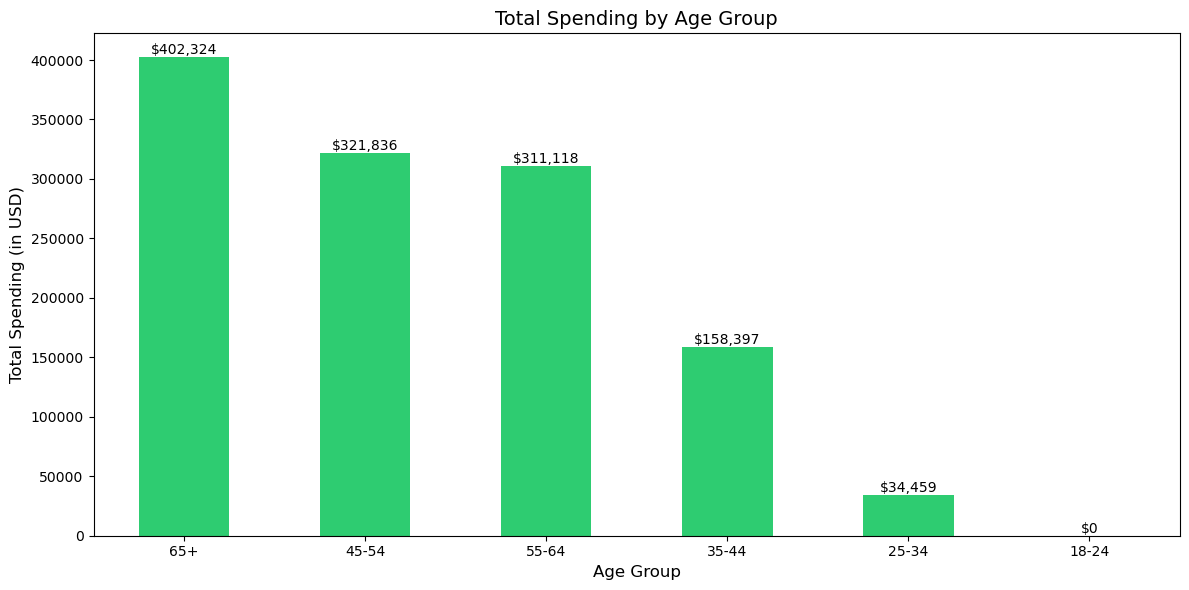

In [40]:
bins = [18, 25, 35, 45, 55, 65, 100]
labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

df['Total Spending'] = df[['MntWines', 'MntFruits', 'MntMeatProducts',
                           'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)

spending_by_age = df.groupby('Age Group', observed=False)['Total Spending'].sum().sort_values(ascending=False)

spending_by_age.plot(kind='bar', figsize=(12, 6), color='#2ecc71')

plt.title('Total Spending by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Spending (in USD)', fontsize=12)
plt.xticks(rotation=0)

ax = plt.gca()
for p in ax.patches:
    ax.annotate(f'${p.get_height():,.0f}', 
                (p.get_x() + p.get_width() / 2, p.get_height()), 
                ha='center', va='bottom', fontsize=10, color='black')

plt.tight_layout()
plt.show()

#### Spending by Sales Channel and Marital Status

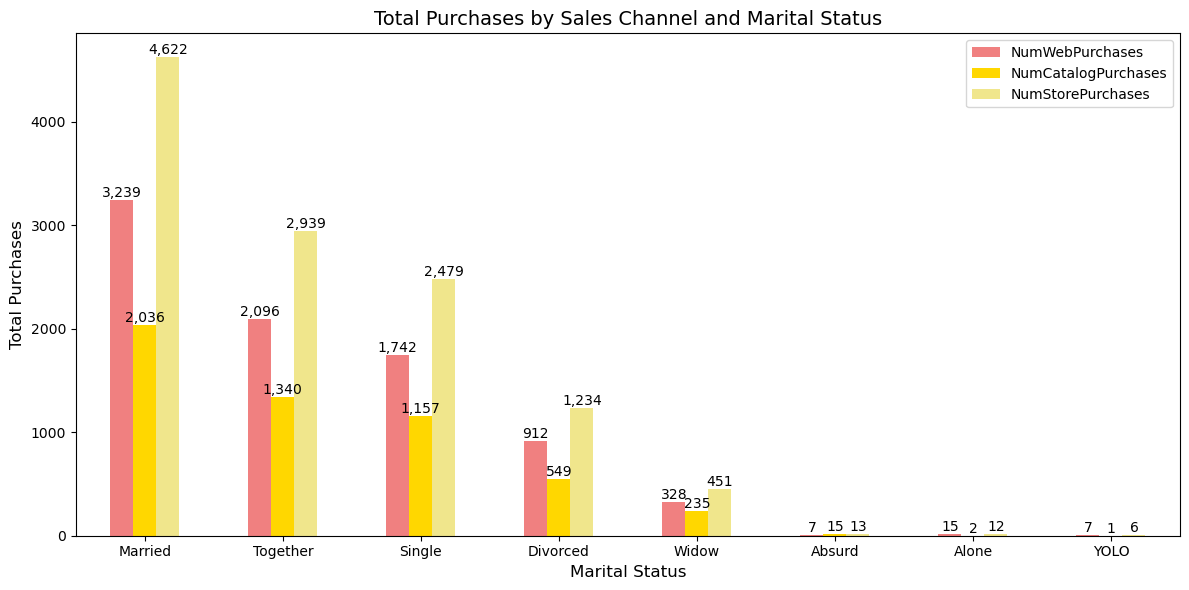

      Purchase Channel  Total Purchases
0    NumStorePurchases            11756
1      NumWebPurchases             8346
2  NumCatalogPurchases             5335


In [42]:
df = df[(df['NumWebPurchases'] >= 0) & (df['NumCatalogPurchases'] >= 0) & (df['NumStorePurchases'] >= 0)]

sales_by_status = df.groupby('Marital_Status')[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].sum()

sales_by_status['TotalPurchases'] = sales_by_status.sum(axis=1)
sales_by_status = sales_by_status.sort_values(by='TotalPurchases', ascending=False)

sales_by_status = sales_by_status.drop(columns='TotalPurchases')

sales_by_status.plot(kind='bar', stacked=False, figsize=(12, 6), color=['#f08080', '#ffd700', '#f0e68c'])

plt.title('Total Purchases by Sales Channel and Marital Status', fontsize=14)
plt.xlabel('Marital Status', fontsize=12)
plt.ylabel('Total Purchases', fontsize=12)
plt.xticks(rotation=0)

ax = plt.gca()  
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=10, color='black')

plt.tight_layout()
plt.show()

purchase_frequency = df[['NumStorePurchases', 'NumWebPurchases', 'NumCatalogPurchases']].sum()

purchase_frequency_df = pd.DataFrame(purchase_frequency).reset_index()
purchase_frequency_df.columns = ['Purchase Channel', 'Total Purchases']

print(purchase_frequency_df)

### Customer Activity
***

#### Relationship Between Website Visits and Online Purchases

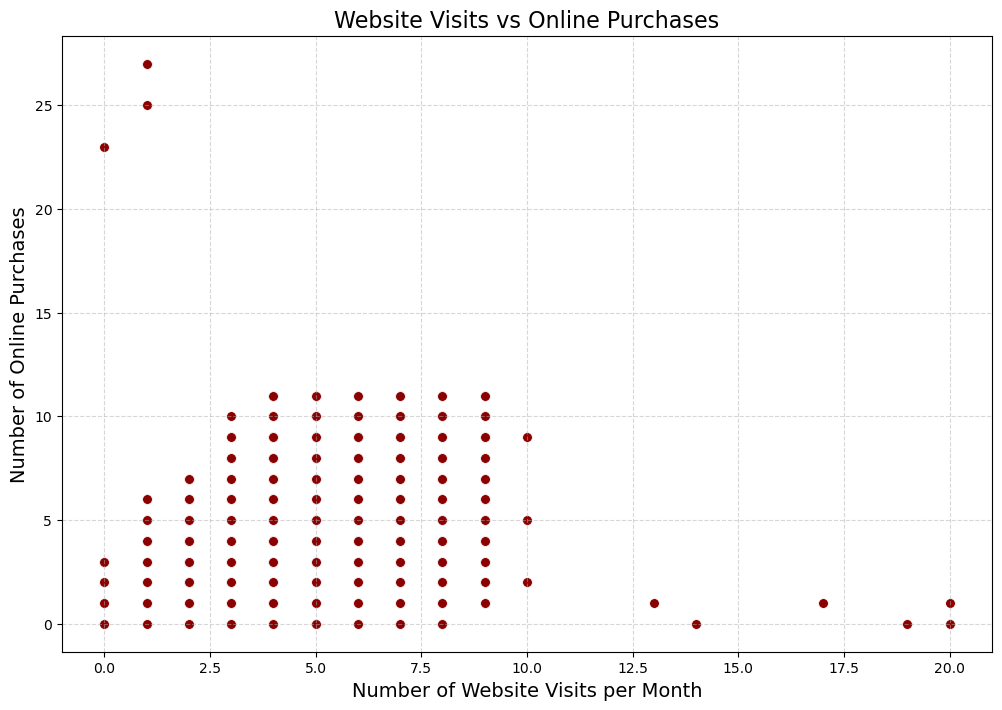

In [45]:
plt.figure(figsize=(12, 8))

sns.scatterplot(x=df['NumWebVisitsMonth'], y=df['NumWebPurchases'], color='darkred', s=50)

plt.title('Website Visits vs Online Purchases', fontsize=16)
plt.xlabel('Number of Website Visits per Month', fontsize=14)
plt.ylabel('Number of Online Purchases', fontsize=14)

plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

#### Relationship Between Recency and Frequency in Customer Purchases

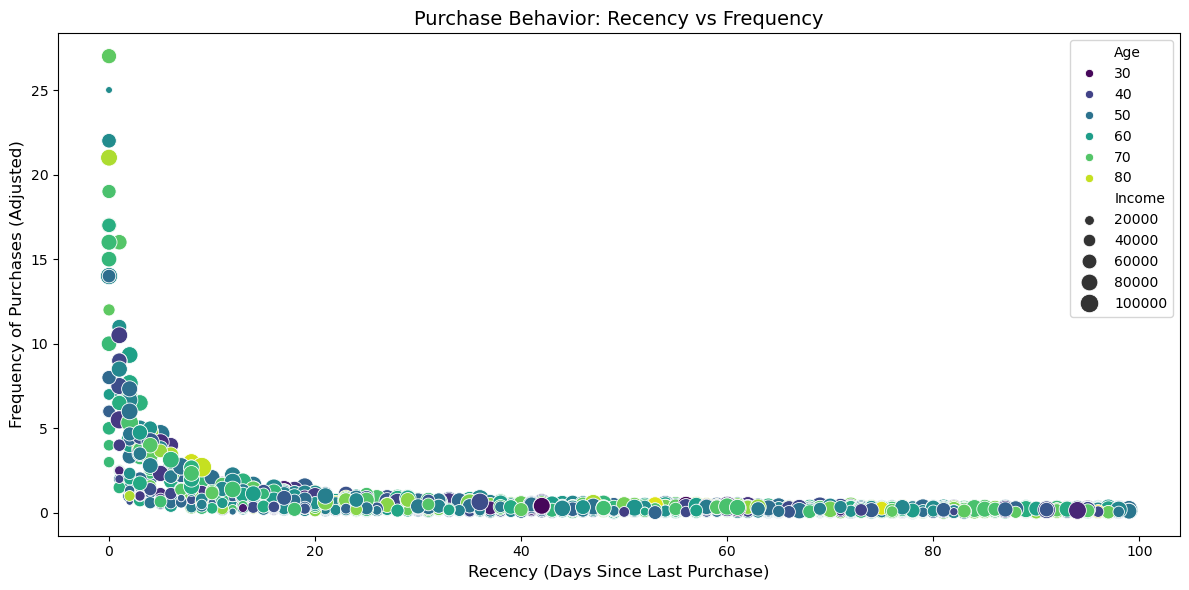

In [47]:
df['Recency_Frequency'] = df['NumStorePurchases'] + df['NumWebPurchases'] + df['NumCatalogPurchases']
df['Recency_Frequency'] = df['Recency_Frequency'] * (1 / (df['Recency'] + 1))  # Adjust for recency

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Recency', y='Recency_Frequency', hue='Age', palette='viridis', size='Income', sizes=(20, 200))

plt.title('Purchase Behavior: Recency vs Frequency', fontsize=14)
plt.xlabel('Recency (Days Since Last Purchase)', fontsize=12)
plt.ylabel('Frequency of Purchases (Adjusted)', fontsize=12)

plt.tight_layout()
plt.show()

#### Campaign Acceptances by Age Group

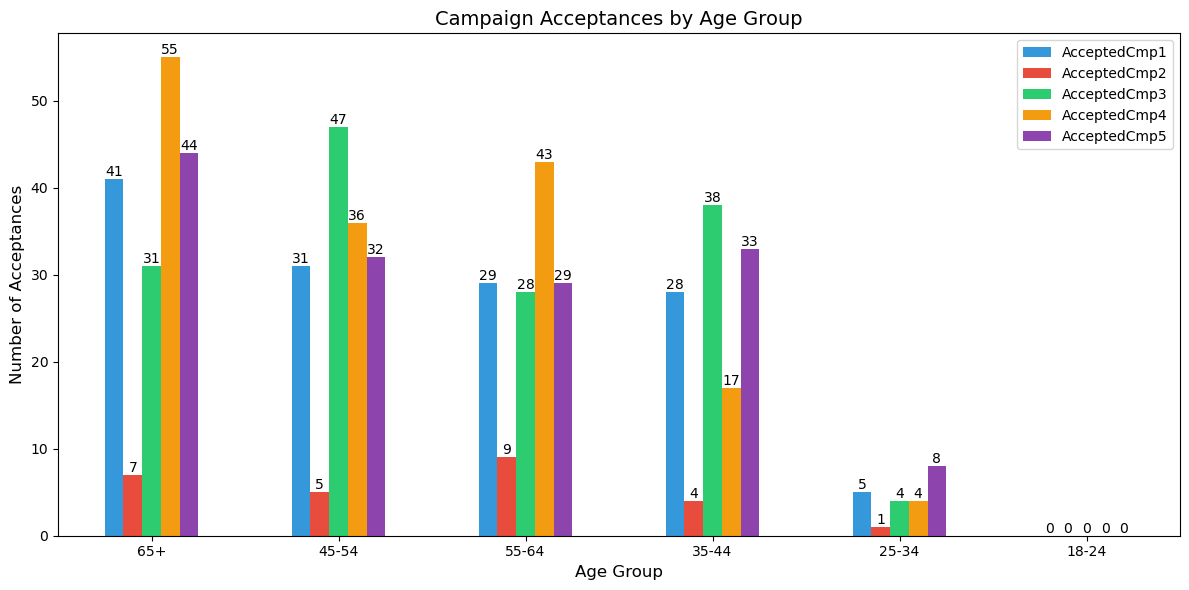

In [49]:
bins = [18, 25, 35, 45, 55, 65, 100] 
labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=False)

campaign_by_age = df.groupby('Age Group', observed=False)[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']].sum()

campaign_by_age['Total Acceptances'] = campaign_by_age.sum(axis=1)
campaign_by_age_sorted = campaign_by_age.sort_values(by='Total Acceptances', ascending=False)

campaign_by_age_sorted.drop('Total Acceptances', axis=1).plot(kind='bar', figsize=(12, 6), color=['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#8e44ad'])

plt.title('Campaign Acceptances by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Number of Acceptances', fontsize=12)
plt.xticks(rotation=0)

ax = plt.gca()  
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=10, color='black')

plt.tight_layout()
plt.show()

#### Correlation Analysis

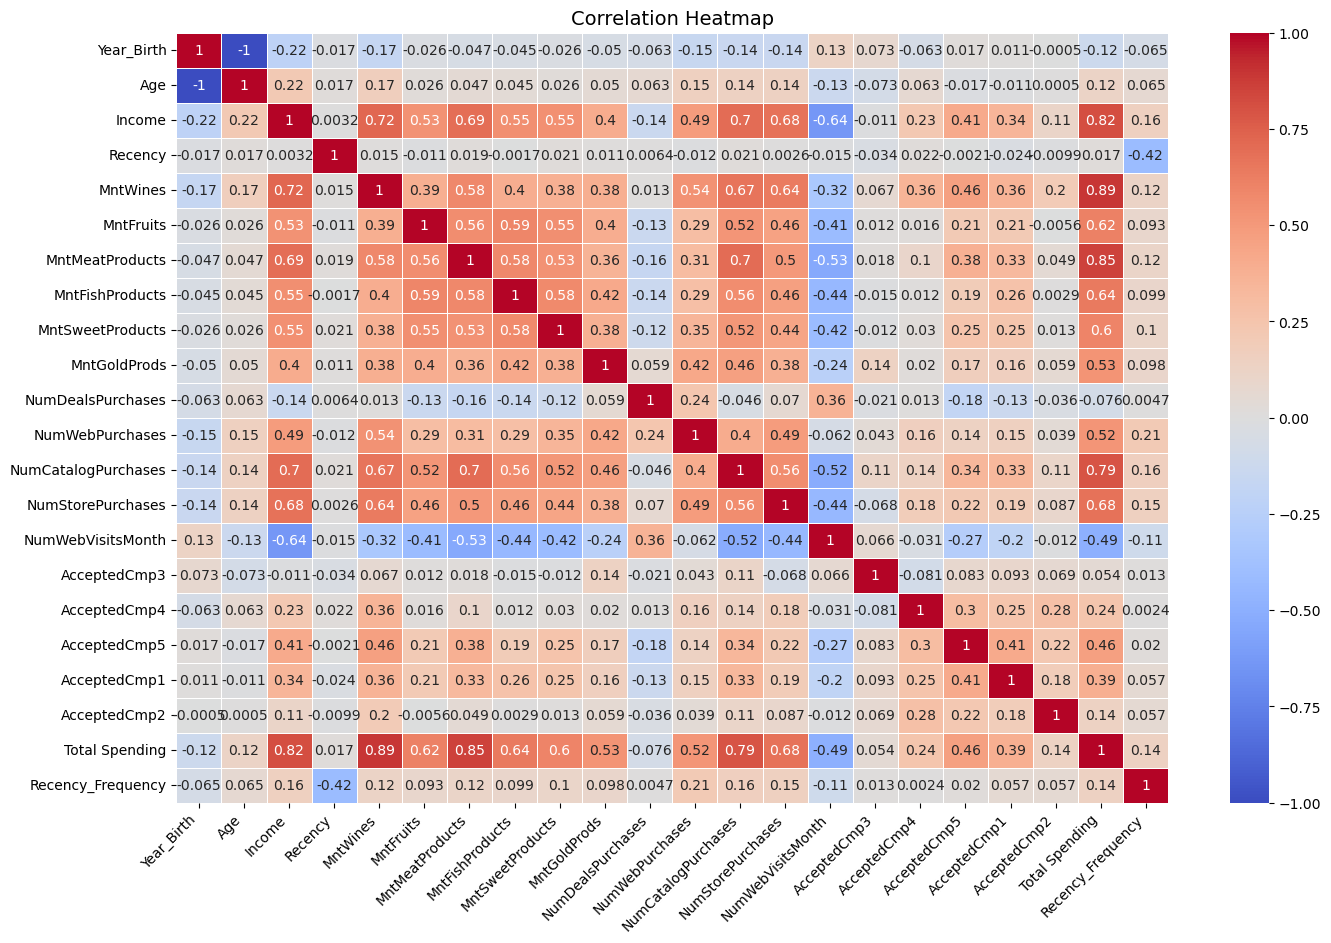

Relationships with correlation > 0.65:
Correlation between Age and Year_Birth: -1.00
Correlation between Year_Birth and Age: -1.00
Correlation between MntWines and Income: 0.72
Correlation between MntMeatProducts and Income: 0.69
Correlation between NumCatalogPurchases and Income: 0.70
Correlation between NumStorePurchases and Income: 0.68
Correlation between Total Spending and Income: 0.82
Correlation between Income and MntWines: 0.72
Correlation between NumCatalogPurchases and MntWines: 0.67
Correlation between Total Spending and MntWines: 0.89
Correlation between Income and MntMeatProducts: 0.69
Correlation between NumCatalogPurchases and MntMeatProducts: 0.70
Correlation between Total Spending and MntMeatProducts: 0.85
Correlation between Income and NumCatalogPurchases: 0.70
Correlation between MntWines and NumCatalogPurchases: 0.67
Correlation between MntMeatProducts and NumCatalogPurchases: 0.70
Correlation between Total Spending and NumCatalogPurchases: 0.79
Correlation between 

In [51]:
numeric_df = df.select_dtypes(include=[np.number])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(16, 10)) 
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap", fontsize=14)  
plt.xticks(rotation=45, ha="right")  
plt.yticks(rotation=0)  
plt.show()

high_corr_pairs = []

for col in corr_matrix.columns:
    for row in corr_matrix.index:
        if abs(corr_matrix.loc[row, col]) > 0.65 and col != row:
            high_corr_pairs.append((row, col, corr_matrix.loc[row, col]))

print("Relationships with correlation > 0.65:")
for pair in high_corr_pairs:
    print(f"Correlation between {pair[0]} and {pair[1]}: {pair[2]:.2f}")


In [52]:
df.columns

Index(['Year_Birth', 'Age', 'Education', 'Marital_Status', 'Income',
       'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3',
       'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2',
       'Age Group', 'Total Spending', 'Recency_Frequency'],
      dtype='object')

## Clustering

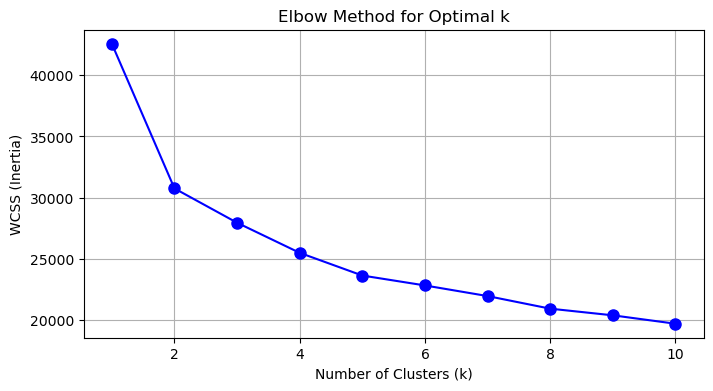

Optimal number of clusters: 3


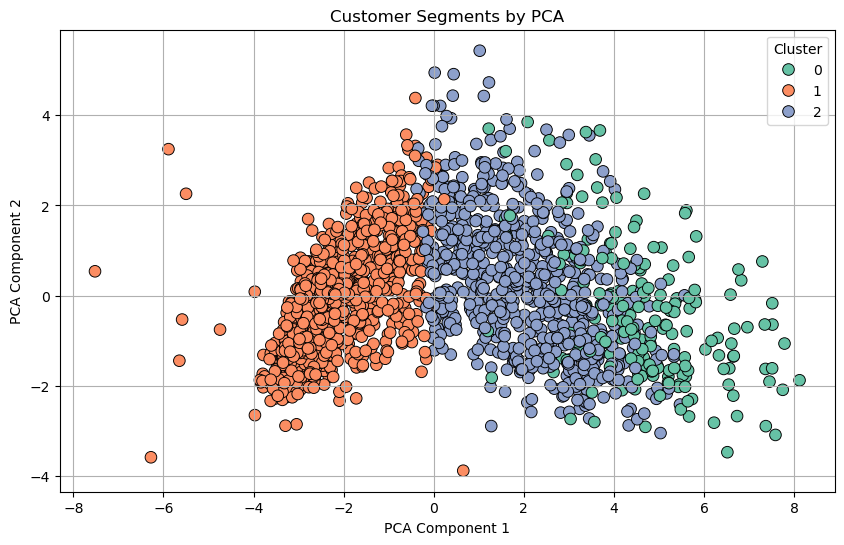


Cluster Summary (Mean values per feature):


,Age,Income,Recency,MntWines,MntMeatProducts,MntFruits,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Total Spending,Recency_Frequency,Count
Cluster,,,,,,,,,,,,,,,,,,,,,
0,55.84,80139.19,50.37,840.17,474.65,58.11,87.34,66.29,75.64,1.18,...,8.45,3.16,0.55,0.11,0.14,0.36,0.72,1602.20,2.51,203
1,54.35,36897.01,49.07,73.83,31.35,5.49,8.13,5.58,19.17,2.37,...,3.59,6.46,0.01,0.00,0.07,0.03,0.00,143.55,7.36,1102
2,58.96,66197.33,48.76,505.65,284.37,49.38,68.50,49.53,72.57,2.58,...,8.41,4.21,0.02,0.00,0.07,0.07,0.00,1030.00,2.55,723


In [54]:
df['Total Spending'] = df[['MntWines', 'MntMeatProducts', 'MntFruits',
                           'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']].sum(axis=1)
df['Recency_Frequency'] = df['Recency'] / (
    df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases'] + 1)

features = ['Age', 'Income', 'Recency', 'MntWines', 'MntMeatProducts', 'MntFruits',
            'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases',
            'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
            'NumWebVisitsMonth', 'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
            'AcceptedCmp4', 'AcceptedCmp5', 'Total Spending', 'Recency_Frequency']

df_clustering = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clustering)

wcss = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss, 'bo-', markersize=8)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

kl = KneeLocator(K_range, wcss, curve='convex', direction='decreasing')
optimal_k = kl.elbow
print(f"Optimal number of clusters: {optimal_k}")

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init='auto')
cluster_labels = kmeans.fit_predict(X_scaled)

df['Cluster'] = cluster_labels

pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_components[:, 0], y=pca_components[:, 1],
                hue=df['Cluster'], palette='Set2', s=70, edgecolor='black')
plt.title('Customer Segments by PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

cluster_summary = df.groupby('Cluster')[features].mean().round(2)
cluster_sizes = df['Cluster'].value_counts().sort_index()
cluster_summary['Count'] = cluster_sizes

print("\nCluster Summary (Mean values per feature):")
display(cluster_summary)

## Classification

In [56]:
df['Target'] = df[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']].sum(axis=1)
df['Target'] = df['Target'].apply(lambda x: 1 if x > 0 else 0) 

X = df[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'MntWines', 'MntFruits', 'MntMeatProducts', 
        'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth']]
y = df['Target'] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f'Original class distribution: {y_train.value_counts()}')
print(f'Balanced class distribution: {y_train_balanced.value_counts()}')

Original class distribution: Target
0    1294
1     328
Name: count, dtype: int64
Balanced class distribution: Target
0    1294
1    1294
Name: count, dtype: int64


Logistic Regression Results:
Accuracy: 0.919
AUC: 0.947
              precision    recall  f1-score   support

           0       1.00      0.89      0.94       311
           1       0.74      1.00      0.85        95

    accuracy                           0.92       406
   macro avg       0.87      0.95      0.90       406
weighted avg       0.94      0.92      0.92       406



C:\Users\amand\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


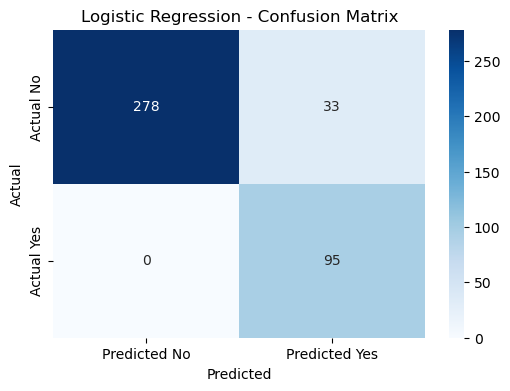

Random Forest Results:
Accuracy: 0.946
AUC: 0.965
              precision    recall  f1-score   support

           0       1.00      0.93      0.96       311
           1       0.81      1.00      0.90        95

    accuracy                           0.95       406
   macro avg       0.91      0.96      0.93       406
weighted avg       0.96      0.95      0.95       406



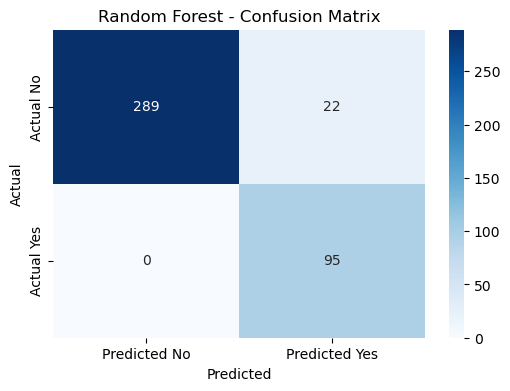

Decision Tree Results:
Accuracy: 0.800
AUC: 0.855
              precision    recall  f1-score   support

           0       0.98      0.75      0.85       311
           1       0.54      0.96      0.69        95

    accuracy                           0.80       406
   macro avg       0.76      0.86      0.77       406
weighted avg       0.88      0.80      0.81       406



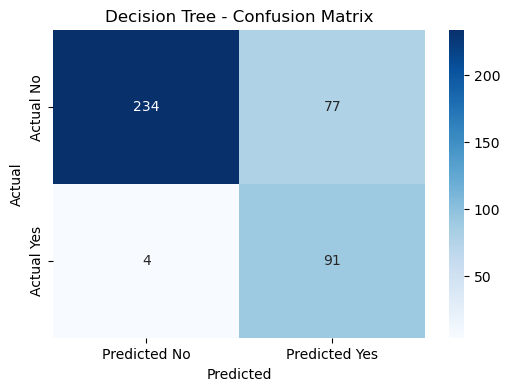

XGBoost Results:
Accuracy: 0.951
AUC: 0.968
              precision    recall  f1-score   support

           0       1.00      0.94      0.97       311
           1       0.83      1.00      0.90        95

    accuracy                           0.95       406
   macro avg       0.91      0.97      0.94       406
weighted avg       0.96      0.95      0.95       406



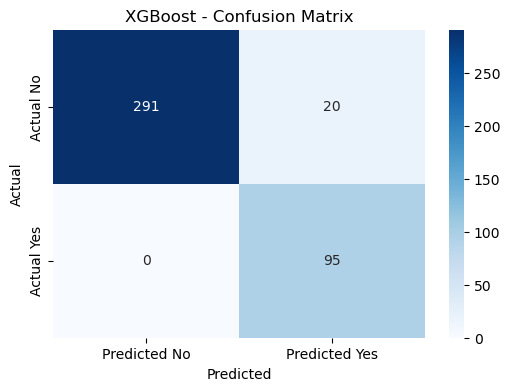

In [57]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(random_state=42, max_iter=500)
logreg.fit(X_train_balanced, y_train_balanced)
y_pred_logreg = logreg.predict(X_test)

print("Logistic Regression Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_logreg):.3f}")
print(f"AUC: {roc_auc_score(y_test, y_pred_logreg):.3f}")
print(classification_report(y_test, y_pred_logreg))
logreg_cm = confusion_matrix(y_test, y_pred_logreg)

plt.figure(figsize=(6, 4))
sns.heatmap(logreg_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted No', 'Predicted Yes'], yticklabels=['Actual No', 'Actual Yes'])
plt.title("Logistic Regression - Confusion Matrix")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

rf = RandomForestClassifier(random_state=42, n_estimators=50, max_depth=10)
rf.fit(X_train_balanced, y_train_balanced)
y_pred_rf = rf.predict(X_test)

print("Random Forest Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.3f}")
print(f"AUC: {roc_auc_score(y_test, y_pred_rf):.3f}")
print(classification_report(y_test, y_pred_rf))
rf_cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted No', 'Predicted Yes'], yticklabels=['Actual No', 'Actual Yes'])
plt.title("Random Forest - Confusion Matrix")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

dt = DecisionTreeClassifier(random_state=42, max_depth=3)
dt.fit(X_train_balanced, y_train_balanced)
y_pred_dt = dt.predict(X_test)

print("Decision Tree Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.3f}")
print(f"AUC: {roc_auc_score(y_test, y_pred_dt):.3f}")
print(classification_report(y_test, y_pred_dt))
dt_cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(dt_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted No', 'Predicted Yes'], yticklabels=['Actual No', 'Actual Yes'])
plt.title("Decision Tree - Confusion Matrix")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

xgb = XGBClassifier(random_state=42, max_depth=3, learning_rate=0.05)
xgb.fit(X_train_balanced, y_train_balanced)
y_pred_xgb = xgb.predict(X_test)

print("XGBoost Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.3f}")
print(f"AUC: {roc_auc_score(y_test, y_pred_xgb):.3f}")
print(classification_report(y_test, y_pred_xgb))
xgb_cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 4))
sns.heatmap(xgb_cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted No', 'Predicted Yes'], yticklabels=['Actual No', 'Actual Yes'])
plt.title("XGBoost - Confusion Matrix")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

## Time Series Analysis

In [59]:
df.set_index('Dt_Customer', inplace=True)

monthly_sales_wine = df['MntWines'].resample('ME').sum()  
monthly_sales_fruits = df['MntFruits'].resample('ME').sum() 
monthly_sales_meat = df['MntMeatProducts'].resample('ME').sum() 
monthly_sales_fish = df['MntFishProducts'].resample('ME').sum()
monthly_sales_sweets = df['MntSweetProducts'].resample('ME').sum()  
monthly_sales_gold = df['MntGoldProds'].resample('ME').sum()

trace_wine = go.Scatter(
    x=monthly_sales_wine.index,
    y=monthly_sales_wine,
    mode='lines+markers',
    name='Wine Sales',
    text=[f'Date: {date.strftime("%Y-%m-%d")}<br>Sales: ${sales:,.2f}' for date, sales in zip(monthly_sales_wine.index, monthly_sales_wine)],
    hoverinfo='text'
)

trace_fruits = go.Scatter(
    x=monthly_sales_fruits.index,
    y=monthly_sales_fruits,
    mode='lines+markers',
    name='Fruit Sales',
    text=[f'Date: {date.strftime("%Y-%m-%d")}<br>Sales: ${sales:,.2f}' for date, sales in zip(monthly_sales_fruits.index, monthly_sales_fruits)],
    hoverinfo='text'
)

trace_meat = go.Scatter(
    x=monthly_sales_meat.index,
    y=monthly_sales_meat,
    mode='lines+markers',
    name='Meat Sales',
    text=[f'Date: {date.strftime("%Y-%m-%d")}<br>Sales: ${sales:,.2f}' for date, sales in zip(monthly_sales_meat.index, monthly_sales_meat)],
    hoverinfo='text'
)

trace_fish = go.Scatter(
    x=monthly_sales_fish.index,
    y=monthly_sales_fish,
    mode='lines+markers',
    name='Fish Sales',
    text=[f'Date: {date.strftime("%Y-%m-%d")}<br>Sales: ${sales:,.2f}' for date, sales in zip(monthly_sales_fish.index, monthly_sales_fish)],
    hoverinfo='text'
)

trace_sweets = go.Scatter(
    x=monthly_sales_sweets.index,
    y=monthly_sales_sweets,
    mode='lines+markers',
    name='Sweets Sales',
    text=[f'Date: {date.strftime("%Y-%m-%d")}<br>Sales: ${sales:,.2f}' for date, sales in zip(monthly_sales_sweets.index, monthly_sales_sweets)],
    hoverinfo='text'
)

trace_gold = go.Scatter(
    x=monthly_sales_gold.index,
    y=monthly_sales_gold,
    mode='lines+markers',
    name='Gold Sales',
    text=[f'Date: {date.strftime("%Y-%m-%d")}<br>Sales: ${sales:,.2f}' for date, sales in zip(monthly_sales_gold.index, monthly_sales_gold)],
    hoverinfo='text'
)

layout = go.Layout(
    title='Monthly Product Sales',
    xaxis=dict(title='Month'),
    yaxis=dict(title='Sales Amount'),
    hovermode='closest'
)

fig = go.Figure(data=[trace_wine, trace_fruits, trace_meat, trace_fish, trace_sweets, trace_gold], layout=layout)

fig.show()

In [60]:
print("\n=== Wine Sales Stationarity Test ===")
result = adfuller(monthly_sales_wine)

print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
print('Critical Values:')
for key, value in result[4].items():
    print(f'\t{key}: {value}')

if result[1] < 0.05:
    print("The wine sales time series is stationary (p-value < 0.05).")
else:
    print("The wine sales time series is non-stationary (p-value >= 0.05).")

first_diff = monthly_sales_wine.diff().dropna()
second_diff = first_diff.diff().dropna()

result_second_diff = adfuller(second_diff)

print('\nSecond Differencing of Wine Sales:')
print('ADF Statistic: %f' % result_second_diff[0])
print('p-value: %f' % result_second_diff[1])
print('Critical Values:')
for key, value in result_second_diff[4].items():
    print(f'\t{key}: {value}')

if result_second_diff[1] < 0.05:
    print("The wine sales time series is stationary after second differencing (p-value < 0.05).")
else:
    print("The wine sales time series is still non-stationary.")



=== Wine Sales Stationarity Test ===
ADF Statistic: -1.654484
p-value: 0.454703
Critical Values:
	1%: -3.6327426647230316
	5%: -2.9485102040816327
	10%: -2.6130173469387756
The wine sales time series is non-stationary (p-value >= 0.05).

Second Differencing of Wine Sales:
ADF Statistic: -2.999281
p-value: 0.034962
Critical Values:
	1%: -3.7112123008648155
	5%: -2.981246804733728
	10%: -2.6300945562130176
The wine sales time series is stationary after second differencing (p-value < 0.05).


In [61]:
print("\n=== Meat Sales Stationarity Test ===")
result_meat = adfuller(monthly_sales_meat)

print('ADF Statistic: %f' % result_meat[0])
print('p-value: %f' % result_meat[1])
print('Critical Values:')
for key, value in result_meat[4].items():
    print(f'\t{key}: {value}')

if result_meat[1] < 0.05:
    print("The meat sales time series is stationary (p-value < 0.05).")
else:
    print("The meat sales time series is non-stationary (p-value >= 0.05).")

first_diff_meat = monthly_sales_meat.diff().dropna()
second_diff_meat = first_diff_meat.diff().dropna()

result_second_diff_meat = adfuller(second_diff_meat)

print('\nSecond Differencing of Meat Sales:')
print('ADF Statistic: %f' % result_second_diff_meat[0])
print('p-value: %f' % result_second_diff_meat[1])
print('Critical Values:')
for key, value in result_second_diff_meat[4].items():
    print(f'\t{key}: {value}')

if result_second_diff_meat[1] < 0.05:
    print("The meat sales time series is stationary after second differencing (p-value < 0.05).")
else:
    print("The meat sales time series is still non-stationary.")


=== Meat Sales Stationarity Test ===
ADF Statistic: -1.797911
p-value: 0.381499
Critical Values:
	1%: -3.6327426647230316
	5%: -2.9485102040816327
	10%: -2.6130173469387756
The meat sales time series is non-stationary (p-value >= 0.05).

Second Differencing of Meat Sales:
ADF Statistic: -5.393218
p-value: 0.000004
Critical Values:
	1%: -3.6790595944893187
	5%: -2.9678817237279103
	10%: -2.6231583472057074
The meat sales time series is stationary after second differencing (p-value < 0.05).



=== ARIMA for Wine Sales ===
                               SARIMAX Results                                
Dep. Variable:               MntWines   No. Observations:                   36
Model:                 ARIMA(1, 2, 1)   Log Likelihood                -346.501
Date:                Sun, 06 Apr 2025   AIC                            699.003
Time:                        16:14:38   BIC                            703.582
Sample:                    01-31-2012   HQIC                           700.564
                         - 12-31-2014                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0328      0.268     -0.122      0.903      -0.557       0.492
ma.L1         -0.9235      0.185     -4.993      0.000      -1.286      -0.561
sigma2      5.643e+07 

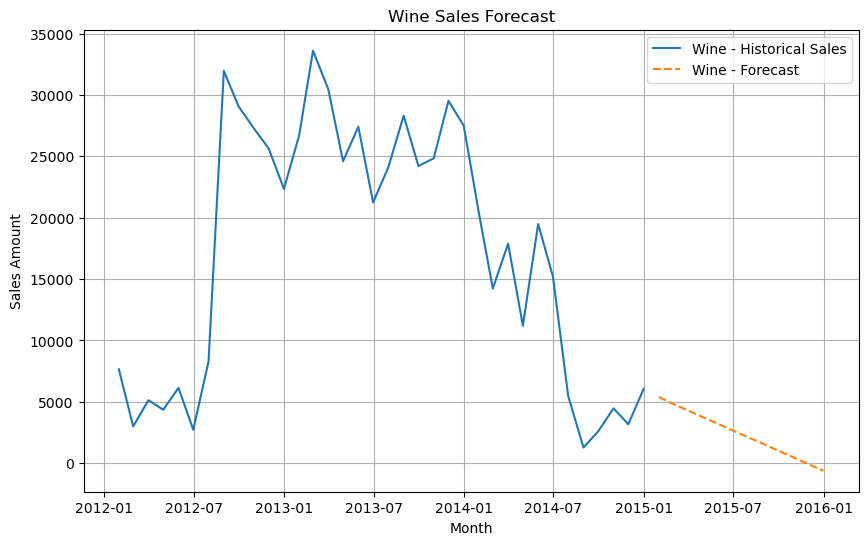


=== ARIMA for Meat Sales ===
                               SARIMAX Results                                
Dep. Variable:        MntMeatProducts   No. Observations:                   36
Model:                 ARIMA(1, 2, 1)   Log Likelihood                -324.761
Date:                Sun, 06 Apr 2025   AIC                            655.521
Time:                        16:14:38   BIC                            660.100
Sample:                    01-31-2012   HQIC                           657.083
                         - 12-31-2014                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0326      0.227      0.143      0.886      -0.413       0.478
ma.L1         -0.9989      0.190     -5.245      0.000      -1.372      -0.626
sigma2      1.078e+07 

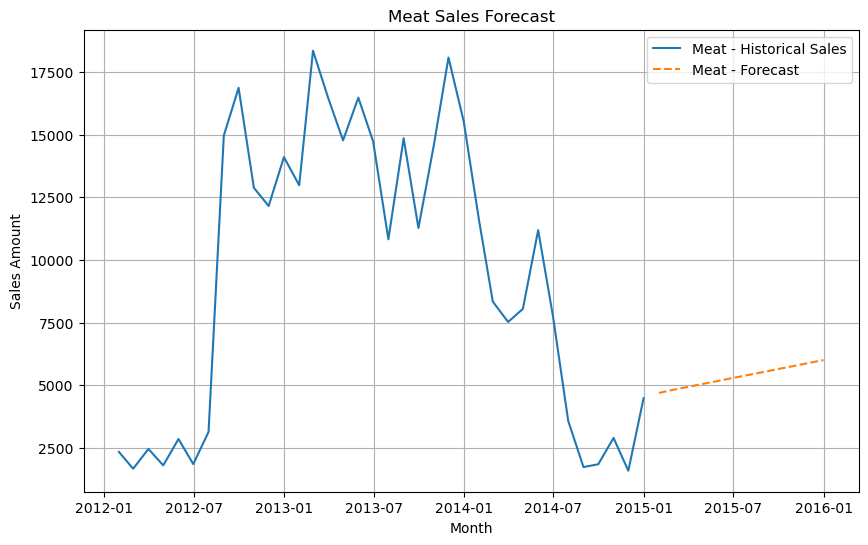

In [102]:
def run_arima_analysis(series, label, order=(1, 2, 1)):
    print(f"\n=== ARIMA for {label} Sales ===")
    
    model = ARIMA(series, order=order)
    model_fit = model.fit()
    print(model_fit.summary())
    
    forecast = model_fit.forecast(steps=12)
    
    actual_values = np.random.rand(12) * 1000

    mae = mean_absolute_error(actual_values, forecast)
    mse = mean_squared_error(actual_values, forecast)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((actual_values - forecast) / actual_values)) * 100
    r2 = r2_score(actual_values, forecast)

    print(f"{label} - MAE: {mae}")
    print(f"{label} - MSE: {mse}")
    print(f"{label} - RMSE: {rmse}")
    print(f"{label} - MAPE: {mape}%")
    print(f"{label} - R²: {r2}")

    last_date = series.index[-1]
    future_dates = pd.date_range(start=last_date + pd.offsets.MonthEnd(1), periods=12, freq='ME')

    plt.figure(figsize=(10, 6))
    plt.plot(series, label=f'{label} - Historical Sales')
    plt.plot(future_dates, forecast, label=f'{label} - Forecast', linestyle='--')
    plt.title(f'{label} Sales Forecast')
    plt.xlabel('Month')
    plt.ylabel('Sales Amount')
    plt.legend()
    plt.grid(True)
    plt.show()

run_arima_analysis(monthly_sales_wine, 'Wine', order=(1, 2, 1))
run_arima_analysis(monthly_sales_meat, 'Meat', order=(1, 2, 1))